In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("/content/insurance_claims_dataset.csv")
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Claim_ID           50000 non-null  object 
 1   Customer_ID        50000 non-null  object 
 2   Policy_Number      50000 non-null  object 
 3   Age                50000 non-null  int64  
 4   Gender             50000 non-null  object 
 5   Region             50000 non-null  object 
 6   Policy_Type        50000 non-null  object 
 7   Premium_Amount     50000 non-null  float64
 8   Coverage_Amount    50000 non-null  float64
 9   Claim_Amount       50000 non-null  float64
 10  Claim_Type         50000 non-null  object 
 11  Credit_Score       50000 non-null  int64  
 12  Fraud_Risk_Score   50000 non-null  float64
 13  Fraud_Flag         50000 non-null  object 
 14  Claim_Status       50000 non-null  object 
 15  Settlement_Amount  50000 non-null  float64
dtypes: float64(5), int64(2

,Claim_ID,Customer_ID,Policy_Number,Age,Gender,Region,Policy_Type,Premium_Amount,Coverage_Amount,Claim_Amount,Claim_Type,Credit_Score,Fraud_Risk_Score,Fraud_Flag,Claim_Status,Settlement_Amount
0,CLM000001,CUST018311,POL0285346,79,Male,West,Home,3264.23,56380.37,8140.64,Accident,529,91.93,Yes,Under Review,4330.86
1,CLM000002,CUST003854,POL0518267,78,Female,West,Home,4937.85,98556.51,32997.15,Accident,331,82.90,Yes,Under Review,30106.34
2,CLM000003,CUST018067,POL0278802,57,Male,West,Health,3952.90,33481.54,14873.17,Property,642,30.69,No,Approved,10424.77
3,CLM000004,CUST007487,POL0372362,66,Male,North,Health,579.12,24701.69,616.78,Property,411,68.15,No,Approved,431.01
4,CLM000005,CUST011899,POL0882135,21,Female,East,Home,676.23,28416.22,42049.70,Theft,714,45.04,No,Approved,27957.75


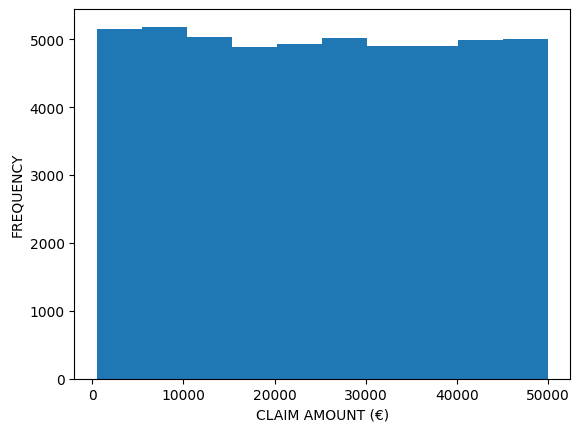

In [6]:
## Histogram : Analyse the distribution of Claim_Amount

claim_am = df['Claim_Amount']
plt.hist(claim_am)
plt.xlabel("CLAIM AMOUNT (€)")
plt.ylabel("FREQUENCY")
plt.show()

## Uniform distribution across claim amounts

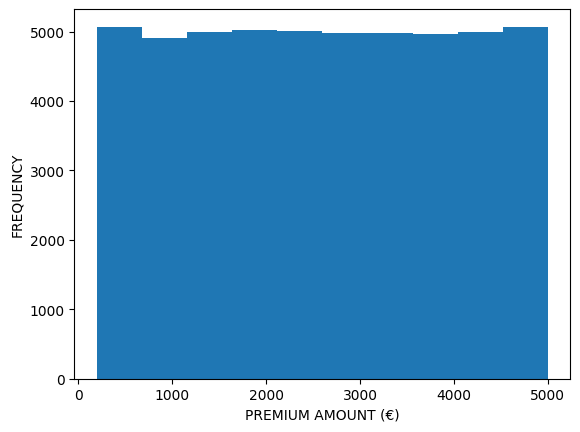

In [7]:
## Histogram : Analyse the distribution of Premium_Amount

premium_am = df['Premium_Amount']
plt.hist(premium_am)
plt.xlabel("PREMIUM AMOUNT (€)")
plt.ylabel("FREQUENCY")
plt.show()

## Unifrom distribution across premium amounts

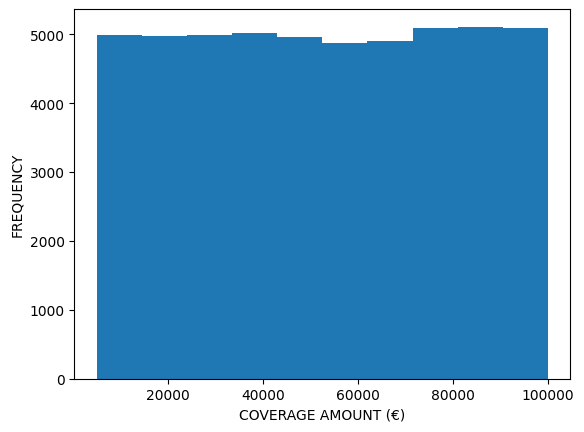

In [8]:
## Histogram : Analyse the distribution of Coverage_Amount

coverage_am = df['Coverage_Amount']
plt.hist(coverage_am)
plt.xlabel("COVERAGE AMOUNT (€)")
plt.ylabel("FREQUENCY")
plt.show()

## Uniform distribution across coverage amount

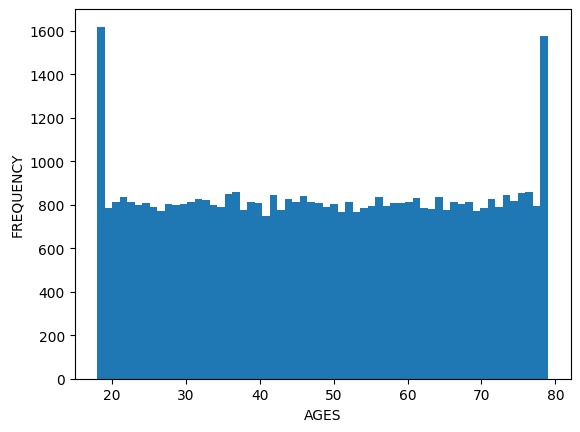

MINIMUM AGE =  18
MAXIMUM AGE =  79
FREQUENCY of policy holders between the AGE of 18-20 =  2406
FREQUENCY of policy holders between the AGE of 77-79 =  2373


In [32]:
## Histogram : Analyse the distribution of Age Groups

age = df["Age"]
plt.hist(age, bins=60)
plt.xlabel("AGES")
plt.ylabel("FREQUENCY")
plt.show()

print("MINIMUM AGE = ", min(age))
print("MAXIMUM AGE = ", max(age))
## Minimum Age is 18, Maximum Age is 79

age_18_20 = df[df["Age"].isin([18, 19, 20])]
age_77_79 = df[df["Age"].isin([77, 78, 79])]
print("FREQUENCY of policy holders between the AGE of 18-20 = ", len(age_18_20))
print("FREQUENCY of policy holders between the AGE of 77-79 = ", len(age_77_79))
## We can see that the frequency of claims across different age groups is uniform,
## except for the frequencies of the very young policy holders between the ages of 18-20
## and eldery policy holders between the ages of 77-79.

**Step 1: Exploratory Data Analysis & Data Quality Checks**

Before jumping into risk calculations, inspect the health and structure of your dataset.
Verify Row Counts & Uniqueness: Ensure key fields like claim_id and customer_id are populated and check for duplicates.

Identify Missing Values: Search for NULL values across critical columns like claim_amount, credit_score, or settlement_amount.

Examine Outliers & Distributions: Check min, max, average, and median values for financial fields (claim_amount, premium_amount, coverage_amount) to detect extreme values or anomalies.


**Step 2: Customer & Claim Profiling (Baseline Metrics)**

Establish baseline behavioral metrics across different customer and policy segments.

Demographic & Policy Profiling: Aggregate claim counts and total claim volume across attributes like age groups, gender, region, and policy_type.
Financial Risk Ratios: Calculate calculated ratios such as:

Claim-to-Coverage Ratio: Claim Amount/Coverage Amount
Loss-to-Premium Ratio: Claim Amount/Premium Amount
Settlement Ratio Analysis: Calculate the ratio of settled amounts to requested amounts (Settlement Amount/Claim Amount) by policy type and claim status.


**Step 3: Define Fraud Indicator Rules & Risk Scoring Logic**

Create business rules to identify red flags and score each claim's risk level.

Rule-Based Red Flags (Categorical Indicators): Use conditional logic (e.g., CASE WHEN) to assign flags for suspicious conditions:

High claim amount relative to coverage limit.
Low credit score combined with a high claim amount.
High fraud risk score or existing fraud flag.

Composite Fraud Risk Score: Combine individual flags into a single numerical risk score or risk tier (e.g., Low Risk, Medium Risk, High Risk, Critical).

**Step 4: High-Risk Segment & Pattern Identification**

Analyze the distribution of suspicious claims across your business dimensions to uncover patterns.

High-Risk Segment Aggregation: Group data by region, policy_type, and claim_type to identify which categories hold the highest concentration of high-risk flags.

Comparative Profiling: Compare average metrics (e.g., average credit score, average premium, average claim size) of flagged fraudulent claims vs. legitimate claims.


**Step 5: Advanced SQL Techniques (Refining the Analysis)**

Use advanced SQL features to make your analysis dynamic and reusable.

Window Functions (OVER, RANK, NTILE):
Rank claims by risk within each region or policy type.
Segment customers into credit score or claim amount deciles/quartiles (NTILE).

CTEs & Subqueries: Break down complex multi-step risk scoring models into clean, readable Common Table Expressions.

Views & Summary Tables: Create database views (e.g., vw_high_risk_claims or vw_fraud_summary_by_region) so stakeholders or dashboard tools can easily query final insights.


**Step 6: Documentation & Portfolio Presentation**

Package your SQL queries into a clean project deliverable.

Executive Summary: Highlight 3–5 key findings (e.g., "Policy Type X accounts for 40% of high-risk claims despite making up only 15% of total volume").

Key Visualizations: Connect your SQL queries or views to a visualization tool (e.g., Tableau, Power BI, or Python/Excel) to chart risk distributions.

Repository Structure: Organize your project with clear subfolders for data, SQL scripts (01_eda.sql, 02_profiling.sql, 03_risk_scoring.sql), and a well-documented README.